## **Loading The Dataset**

In [16]:
# Building a Regression MLP Using the Sequential API
#pip install tensorflow
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

In [17]:
# The House Prices Dataset
housing = fetch_california_housing()
print("Examples = ",housing.data.shape ," Labels = ", housing.target.shape)


Examples =  (20640, 8)  Labels =  (20640,)


In [18]:
X = housing.data
Y = housing.target

print("Example 0 : ",housing.data[0])
print("\nLabel 0 : ",housing.target[0])


Example 0 :  [   8.3252       41.            6.98412698    1.02380952  322.
    2.55555556   37.88       -122.23      ]

Label 0 :  4.526


In [19]:
Y[0]

np.float64(4.526)

In [20]:
# Dataset to DataFrame
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["price"] = pd.Series(housing.target)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [21]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [22]:
# Dropping the duplicate rows
duplicate_rows = df[df.duplicated()]
print("number of duplicate rows : ",duplicate_rows.shape)

# df.drop_duplicates(inplace=True)

number of duplicate rows :  (0, 9)


SUM : 
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
price         0
dtype: int64


<Axes: >

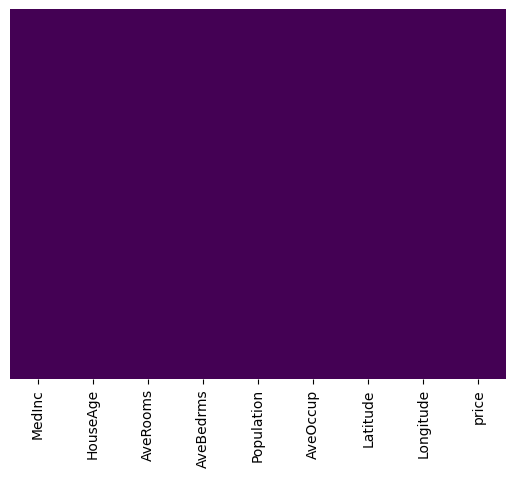

In [23]:
# To check missing values
print("SUM : \n",df.isnull().sum())
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")


In [24]:
X_data = df.drop(["price"], axis=1).values
y_data = df["price"].values
print("X_data : ",X_data.shape," y_data : ",y_data.shape)

X_data :  (20640, 8)  y_data :  (20640,)


In [25]:
# Standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_data)
X_sts = scaler.transform(X_data)

In [26]:
# Split into Input and Output Elements
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(X_sts,
              y_data, test_size= 0.20, random_state=100)
# Val set
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full
                                                      , test_size= 0.10)

print("X_train  = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test   = ",X_test.shape ," y_test = ", y_test.shape)
print("X_valid  = ",X_valid.shape ," y_valid = ", y_valid.shape)


X_train  =  (14860, 8)  y_train =  (14860,)
X_test   =  (4128, 8)  y_test =  (4128,)
X_valid  =  (1652, 8)  y_valid =  (1652,)


In [27]:
"""X_train, X_test_full, y_train, y_test_full = train_test_split(X_sts,
              y_data, test_size= 0.30, random_state=100)
# Val set
X_test, X_valid, y_test, y_valid = train_test_split(X_test_full, y_test_full
                                                      , test_size= 0.50)
# train 700
# test 150
# valid 150"""

'X_train, X_test_full, y_train, y_test_full = train_test_split(X_sts, \n              y_data, test_size= 0.30, random_state=100)\n# Val set\nX_test, X_valid, y_test, y_valid = train_test_split(X_test_full, y_test_full\n                                                      , test_size= 0.50)\n# train 700\n# test 150\n# valid 150'

## **Normal CNN**

## Activation function
- tf.keras.activations.linear,"linear"
- tf.keras.activations.relu,"relu"
- tf.keras.activations.leaky_relu,"leaky_relu"
- tf.keras.activations.selu,"selu"
- tf.keras.activations.hard_silu,"hard_silu"
- tf.keras.activations.gelu,"gelu"
- tf.keras.activations.exponential,"exponential"
- tf.keras.activations.sigmoid,"sigmoid"
- tf.keras.activations.softmax,"softmax"
- tf.keras.activations.softplus,"softplus"
- tf.keras.activations.softsign,"softsign"
- tf.keras.activations.tanh,"tanh"
- tf.keras.activations.swish,"swish"
- tf.keras.activations.hard_sigmoid,"hard_sigmoid"


- tf.keras.activations.

In [28]:
type(X_train.shape[1:])

tuple

In [29]:
# Creating the model using the Sequential API
import tensorflow as tf
from tensorflow import keras
model = keras.models.Sequential()
model.add(keras.layers.Dense(100, activation="relu", input_shape = X_train.shape[1:]))  # input_dim = 8
model.add(keras.layers.Dense(25, activation=tf.keras.activations.relu))
model.add(keras.layers.Dense(25, activation="relu"))
model.add(keras.layers.Dense(25, activation="relu"))
model.add(keras.layers.Dense(25, activation="relu"))
model.add(keras.layers.Dense(8, activation="relu"))
model.add(keras.layers.Dense(1, activation="relu")) # price > 0, so, relu

# The model’s summary() method displays all the model’s layers
print(model.summary())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 100)            │           900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 25)             │         2,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,592 (21.84 KB)

 Trainable params: 5,592 (21.84 KB)

 Non-trainable params: 0 (0.00 B)

None


## Optimization
- tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07) || "Adam"
- tf.keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9, momentum=0.0, epsilon=1e-07, centered=False) || "RMSprop"
- tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.01) || "AdamW"
- tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.0, nesterov=False) || "SGD"
- tf.keras.optimizers.Adagrad(learning_rate=0.001, initial_accumulator_value=0.1, epsilon=1e-07) || "Adagrad"
- tf.keras.optimizers.Adadelta(learning_rate=0.001, rho=0.95, epsilon=1e-07) || "Adadelta"
- tf.keras.optimizers.Adamax(learning_rate=0.002, beta_1=0.9, beta_2=0.999, epsilon=1e-07) || "Adamax"
- tf.keras.optimizers.Nadam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07) || "Nadam"






## Loss Function
**Regression**
- tf.keras.losses.MeanSquaredError() || "mse" or "mean_squared_error"
- tf.keras.losses.MeanAbsoluteError() || "mae" or "mean_absolute_error"

**Binary CLassification**
- tf.keras.losses.BinaryCrossentropy() || "binary_crossentropy"

**Multi Classification**
- tf.keras.losses.CategoricalCrossentropy() || "categorical_crossentropy"
- tf.keras.losses.SparseCategoricalCrossentropy() || "sparse_categorical_crossentropy"




## Metrics
**Regression**
- tf.keras.metrics.MeanSquaredError() || "mse" or "mean_squared_error"
- tf.keras.metrics.MeanAbsoluteError() || "mae" or "mean_absolute_error"

**Classification**
- tf.keras.metrics.Accuracy() || "accuracy" or "acc"
- tf.keras.metrics.Precision() || "precision"
- tf.keras.metrics.Recall() || "recall"
- tf.keras.metrics.AUC() || "auc"


In [30]:
# Compiling the model
# https://keras.io/models/sequential/
model.compile(loss="mean_squared_error", optimizer="sgd", metrics=["mae"])

## Train Model
**history = model.fit(X_train, y_train,**

**epochs=150,**

**steps_per_epoch=,**

**batch_size=64,**

**shuffle=True,**

**validation_data=(X_valid,y_valid) or validation_split=0 :1,**

**validation_batch_size=,**

**validation_steps=)**


In [31]:
# Training and evaluating the model
history = model.fit(X_train, y_train, epochs=100, batch_size=128, validation_data=(X_valid, y_valid))
# history = model.fit(X_train, y_train, epochs=30, batch_size=128, validation_split=0.2)


Epoch 1/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.3656 - mae: 0.8416 - val_loss: 0.8726 - val_mae: 0.6546
Epoch 2/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5671 - mae: 0.5559 - val_loss: 0.5377 - val_mae: 0.5537
Epoch 3/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4714 - mae: 0.4971 - val_loss: 0.4720 - val_mae: 0.4619
Epoch 4/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4262 - mae: 0.4675 - val_loss: 0.4596 - val_mae: 0.4976
Epoch 5/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4052 - mae: 0.4538 - val_loss: 0.4671 - val_mae: 0.5138
Epoch 6/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3924 - mae: 0.4469 - val_loss: 0.4024 - val_mae: 0.4477
Epoch 7/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3824 - mae: 0.4406 - val_loss: 0.3917 - val_mae: 0.4216
Epoch 8/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3705 - mae: 0.4319 - val_loss: 0.3711 - val_mae: 0.4219
Epoch 9/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/

In [32]:
history.history

{'loss': [1.3656045198440552,
  0.5670920014381409,
  0.47135651111602783,
  0.42620307207107544,
  0.40519678592681885,
  0.3923540413379669,
  0.3823872208595276,
  0.3704907298088074,
  0.36719074845314026,
  0.37175238132476807,
  0.35618606209754944,
  0.35112515091896057,
  0.35065993666648865,
  0.347196102142334,
  0.3474028706550598,
  0.3431483209133148,
  0.3351971507072449,
  0.3330800235271454,
  0.3405444920063019,
  0.33320778608322144,
  0.32844313979148865,
  0.3344724476337433,
  0.32889267802238464,
  0.323691189289093,
  0.32040026783943176,
  0.3166888654232025,
  0.32168081402778625,
  0.32080718874931335,
  0.31432273983955383,
  0.31473979353904724,
  0.316571444272995,
  0.3120516836643219,
  0.30722153186798096,
  0.30866655707359314,
  0.3124181926250458,
  0.3089199960231781,
  0.3069648742675781,
  0.3021934926509857,
  0.31028643250465393,
  0.30008289217948914,
  0.2982856035232544,
  0.29684978723526,
  0.3005756735801697,
  0.29446062445640564,
  0.3042

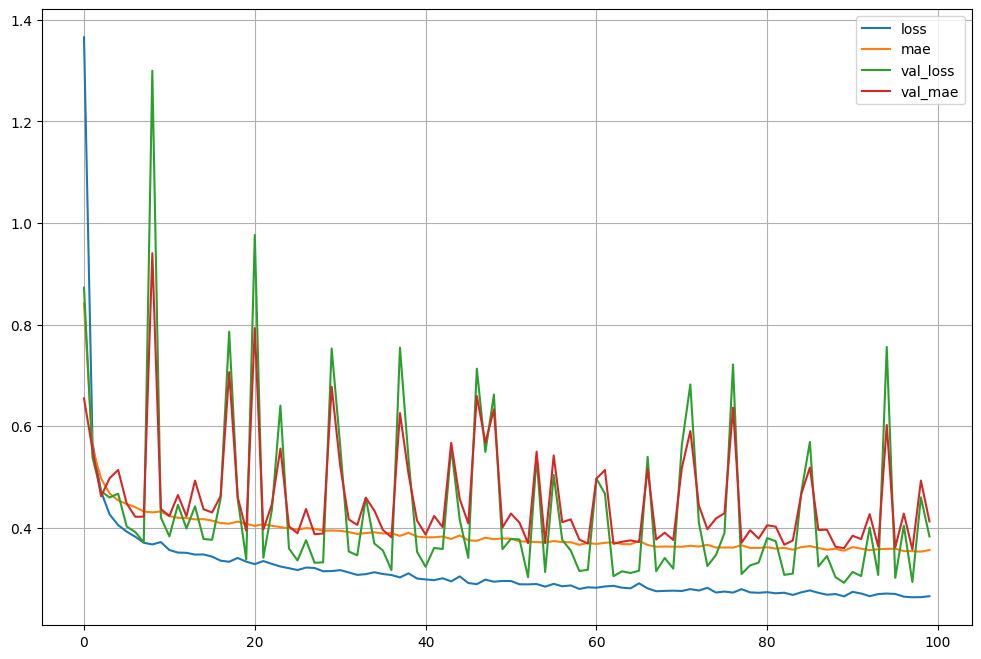

-----------------------------------------------------------------------
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3638 - mae: 0.4006
Loss                   :  0.36377212405204773
Mean Absolute Error     :  0.4005928635597229


In [33]:
# plot the learning curves
import pandas as pd
import matplotlib.pyplot as plt
pd.DataFrame(history.history).plot(figsize=(12, 8))
plt.grid(True)
#plt.gca().set_ylim(0, 1) # set the vertical range to [0-1]
plt.show()

print("-----------------------------------------------------------------------")
# Evaluate the model
model_evaluate = model.evaluate(X_test, y_test)
print("Loss                   : ",model_evaluate[0])
print("Mean Absolute Error     : ",model_evaluate[1])


In [34]:
# Comparison of the actual results with the predicted results
predicted = model.predict(X_test)

# Model evaluation
print("Mean Absolute Error    : ", metrics.mean_absolute_error(y_test, predicted))
print("Mean Squared Error     : ", metrics.mean_squared_error(y_test, predicted))
print("Root Mean Squared Error: ", np.sqrt(metrics.mean_squared_error(y_test, predicted)))
print("r2_score               : ", metrics.r2_score(y_test, predicted))

print("-----------------------------------------------------------------------")
df_data = pd.DataFrame({"Actual": y_test.flatten(), "Predicted": predicted.flatten()})
print(df_data.head(15))
print("-----------------------------------------------------------------------")

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Mean Absolute Error    :  0.40059293782828387
Mean Squared Error     :  0.3637721922151041
Root Mean Squared Error:  0.6031353017483756
r2_score               :  0.7300186039791647
-----------------------------------------------------------------------
    Actual  Predicted
0    2.453   2.802288
1    1.042   0.959692
2    1.462   1.324866
3    1.542   0.998366
4    3.242   2.039209
5    1.411   1.550130
6    2.273   2.096554
7    2.023   2.190654
8    1.702   1.007733
9    3.018   3.376672
10   1.522   1.462119
11   3.081   3.555304
12   4.850   3.684685
13   1.625   2.244479
14   2.250   2.932417
-----------------------------------------------------------------------
